# Финальный экзамен. Анализ данных в Python


## 1. Загрузка данных

Первый столбец Excel использую как индекс, потому что в нём сохранены номера строк. Также исправил кодировку трёх имён, чтобы они корректно отображались в результатах.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

data_dir = Path('.')
if not (data_dir / 'NHL-playoffs-2026.xlsx').exists():
    data_dir = Path('/Users/karimsadykov/Desktop/NES/Количественные методы /Exam')

events = pd.read_excel(data_dir / 'NHL-playoffs-2026.xlsx', index_col=0)
events['Date'] = pd.to_datetime(events['Date'])


def fix_name(value):
    if not isinstance(value, str):
        return value
    try:
        return value.encode('latin1').decode('utf-8')
    except (UnicodeEncodeError, UnicodeDecodeError):
        return value

player_cols = [c for c in events if 'Player on the Ice #' in c or c.endswith("'s Goalie")]
name_cols = player_cols + [f'Player in the Event #{i}' for i in range(1, 4)]
for col in name_cols:
    events[col] = events[col].map(fix_name)

print(events.shape)
display(events.iloc[:10, [2, 3, 4, 9, 12]])

(29710, 38)


,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


## 2. Сводная информация по матчам

Группирую события по `Game ID`. Счёт накопительный, поэтому беру его максимум за матч, а не сумму по событиям. Число овертаймов получаю как максимальный номер периода минус 3

In [2]:
games = events.groupby('Game ID').agg(
    Date=('Date', 'first'),
    **{'Away Team': ('Away Team', 'first'),
       'Home Team': ('Home Team', 'first'),
       'Away Score': ('Cumulated Away Score', 'max'),
       'Home Score': ('Cumulated Home Score', 'max'),
       'Periods': ('Period', 'max')}
)
overtimes = games.pop('Periods').sub(3).clip(lower=0)
games['Outcome'] = overtimes.map(
    lambda n: 'Final' if n == 0 else ('Final/OT' if n == 1 else f'Final/{n}OT')
)
display(games)

,Date,Away Team,Home Team,Away Score,Home Score,Outcome
Game ID,,,,,,
2025030111,2026-04-19,Boston Bruins,Buffalo Sabres,3,4,Final
2025030112,2026-04-21,Boston Bruins,Buffalo Sabres,4,2,Final
2025030113,2026-04-23,Buffalo Sabres,Boston Bruins,3,1,Final
2025030114,2026-04-26,Buffalo Sabres,Boston Bruins,6,1,Final
2025030115,2026-04-28,Boston Bruins,Buffalo Sabres,2,1,Final/OT
...,...,...,...,...,...,...
2025030412,2026-06-04,Vegas Golden Knights,Carolina Hurricanes,3,4,Final/OT
2025030413,2026-06-06,Carolina Hurricanes,Vegas Golden Knights,4,5,Final/2OT
2025030414,2026-06-09,Carolina Hurricanes,Vegas Golden Knights,5,3,Final


## 3. Функция gameInfo

Сведения из сводной таблицы беру по идентификатору матча. Во всех строках вывода сначала хозяева, потом гости, чтобы порядок команд и счёта был одинаковым

In [3]:
def gameInfo(gameId):
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, "
            f"{g['Outcome']}, {g['Date']:%Y-%m-%d})")

print(gameInfo(games.index.min()))
print(gameInfo(games.index.max()))

Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)
Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)


## 4. Число голов за матч

Складываю итоговые голы хозяев и гостей, включая овертаймы. Каждая игра учитывается один раз независимо от её продолжительности.

In [4]:
games['Total Score'] = games['Away Score'] + games['Home Score']
display(games['Total Score'].describe().round(3))

count    82.000
mean      5.927
std       2.260
min       1.000
25%       5.000
50%       6.000
75%       7.000
max      15.000
Name: Total Score, dtype: float64

## 5. Гистограмма числа голов


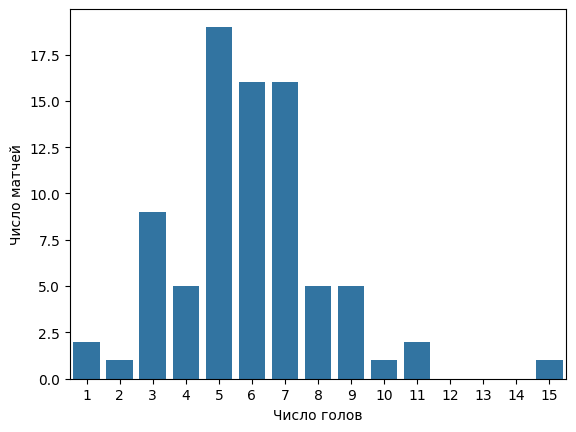

In [5]:
sns.countplot(data=games, x='Total Score', order=range(1, games['Total Score'].max() + 1))
plt.xlabel('Число голов')
plt.ylabel('Число матчей')
plt.show()

На гистограмме видно, что чаще всего в матче забивают 5-7 голов. Среднее - 5,927, медиана - 6. Очень результативные матчи встречаются редко, максимум - 15 голов.

## 6. Самые нерезультативные и результативные матчи

Выбираю все матчи с минимальным и максимальным числом голов, чтобы не потерять игры с одинаковым результатом.

In [6]:
print('Минимум голов:')
print(*[gameInfo(g) for g in games.index[games['Total Score'].eq(games['Total Score'].min())]], sep='\n')
print('Максимум голов:')
print(*[gameInfo(g) for g in games.index[games['Total Score'].eq(games['Total Score'].max())]], sep='\n')

Минимум голов:
Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)
Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)
Максимум голов:
Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)


## 7. Число участников матча

Объединяю поля состава обеих команд и вратарей. Каждую пару «матч, игрок» оставляю один раз: повторные выходы на лёд и присутствие вратаря в двух полях не должны увеличивать число участников

In [7]:
appearances = (events[['Game ID'] + player_cols]
               .melt(id_vars='Game ID', value_name='Player')
               .dropna(subset=['Player'])
               .drop_duplicates(['Game ID', 'Player']))
player_count = appearances.groupby('Game ID').size().rename('Player Count')
most_players = player_count[player_count.eq(player_count.max())].to_frame()
most_players.insert(0, 'Game Info', [gameInfo(g) for g in most_players.index])
display(most_players)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Получилось максимум 40 игроков. Пропуски я не считаю отдельным участником, поэтому результат отличается от 41 в примере условия.

## 8. Расстояние от броска до створа ворот

Ворота имеют ширину 6 футов, поэтому считаю расстояние до ближайшей точки отрезка с координатами Y от -3 до 3. `clip(-3, 3)` даёт координату этой точки. Просто `hypot(x - X, y)` измерял бы расстояние до центра ворот и завышал бы расстояние до створа. Нужные ворота определяю по команде, которая бросает, и стороне защиты хозяев.

In [8]:
shot_types = ['shot-on-goal', 'goal', 'missed-shot']
shot_mask = events['Play Type'].isin(shot_types)
shots = events.loc[shot_mask].copy()
home_shot = shots['Team Making the Play'].eq(shots['Home Team'])
home_defends_left = shots["Home Team's Defending Side"].eq('left')
goal_x = np.where(home_shot.eq(home_defends_left), 89, -89)
x = shots['X Coordinate on the Ice Rink']
y = shots['Y Coordinate on the Ice Rink']

shots['Shot Length'] = np.hypot(x - goal_x, y - y.clip(-3, 3))
events.loc[shot_mask, 'Shot Length'] = shots['Shot Length']
display(events.loc[shot_mask, ['Game ID', 'Play Type', 'Shot Length']].round(3))

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


## 9. Распределения расстояний точных и неточных бросков

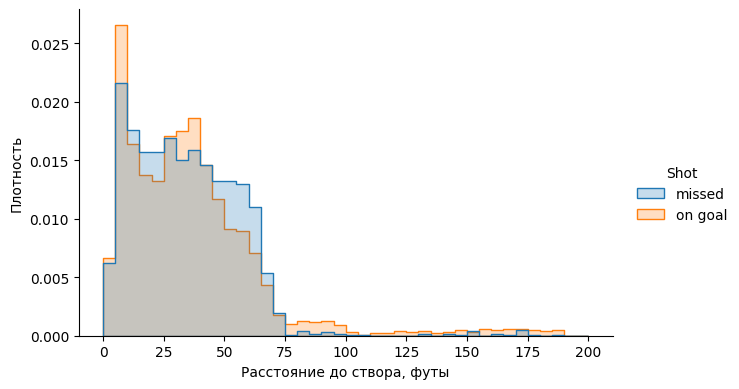

In [9]:
shots['Shot'] = np.where(shots['Play Type'].eq('missed-shot'), 'missed', 'on goal')
sns.displot(data=shots, x='Shot Length', hue='Shot', bins=np.arange(0, 201, 5),
            stat='density', common_norm=False, element='step', height=4, aspect=1.6)
plt.xlabel('Расстояние до створа, футы')
plt.ylabel('Плотность')
plt.show()

Хвост у точных бросков >100 футов думаю связана бросками в пустые ворота: при снятом вратаре команда выбрасывает шайбу из своей зоны, и она попадает в пустые ворота.

Использую одинаковые интервалы по 5 футов и `stat="density", common_norm=False`: площадь каждой гистограммы равна 1. Так сравнивается форма распределений, а разное число точных и неточных бросков не определяет высоту столбцов. При общей нормировке более многочисленная группа получила бы большую суммарную площадь.

## 10. Доля точных бросков каждой команды в каждом матче

Точными считаю `shot-on-goal` и `goal`. В знаменатель входят они же и `missed-shot`; заблокированные броски исключаю, как требуется в условии.

In [10]:
numshots = (shots.groupby(['Game ID', 'Team Making the Play', 'Play Type'])
            .size().unstack(fill_value=0))
numshots['Shot'] = numshots['shot-on-goal'] + numshots['goal']
numshots['Share of Shots on Goal'] = numshots['Shot'] / (numshots['Shot'] + numshots['missed-shot'])
display(numshots['Share of Shots on Goal'].round(3))
print(f"Средняя доля: {numshots['Share of Shots on Goal'].mean():.3f}; "
      f"минимум: {numshots['Share of Shots on Goal'].min():.3f}; "
      f"максимум: {numshots['Share of Shots on Goal'].max():.3f}.")

Средняя доля: 0.639; минимум: 0.353; максимум: 0.860.


Game ID     Team Making the Play
2025030111  Boston Bruins           0.625
            Buffalo Sabres          0.679
2025030112  Boston Bruins           0.614
            Buffalo Sabres          0.636
2025030113  Boston Bruins           0.694
                                    ...  
2025030414  Vegas Golden Knights    0.583
2025030415  Carolina Hurricanes     0.558
            Vegas Golden Knights    0.510
2025030416  Carolina Hurricanes     0.639
            Vegas Golden Knights    0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

В среднем около 64% незаблокированных бросков попадают в створ. При этом точность довольно сильно меняется от матча к матчу и между командами: от 35% до 86%.

## 11. Команды с наибольшей и наименьшей средней точностью

Сначала считаю долю в каждом матче, затем беру среднее этих долей по команде. Так каждый матч имеет одинаковый вес. Если поделить общее число точных бросков на все броски за плей-офф, получится другой показатель, в котором больший вес у матчей с большим числом бросков.

In [11]:
avgnumshots = numshots['Share of Shots on Goal'].groupby('Team Making the Play').mean()
display(avgnumshots.nlargest(5).round(3))
display(avgnumshots.nsmallest(5).round(3))

Team Making the Play
Edmonton Oilers        0.706
Philadelphia Flyers    0.684
Dallas Stars           0.670
Minnesota Wild         0.656
Colorado Avalanche     0.653
Name: Share of Shots on Goal, dtype: float64

Team Making the Play
Pittsburgh Penguins    0.554
Utah Mammoth           0.599
Carolina Hurricanes    0.615
Tampa Bay Lightning    0.626
Buffalo Sabres         0.626
Name: Share of Shots on Goal, dtype: float64

Самая высокая средняя точность у Edmonton Oilers (70,6%), самая низкая у Pittsburgh Penguins (55,4%). Но у Edmonton в среднем 3,500 гола за матч, а у Minnesota Wild 3,727 при точности 65,6%. Доля попаданий в створ и доля голов среди попаданий в створ измеряют разные вещи. По отношению суммарных голов к броскам в створ реализация у Edmonton около 12,4%, у Minnesota около 13,0%; бросков в створ у Minnesota также немного больше: 28,727 против 28,333 за матч. Поэтому высокая точность Edmonton не означает максимальное число голов за игру.

## 12. Среднее число бросков в створ и голов за матч

Для каждой команды делю число бросков в створ и голов на число её матчей. Голы входят в броски в створ. Сравниваю показатели за матч, потому что команды сыграли разное число игр; длительность овертаймов при этом отдельно не учитываю.

In [12]:
avgshots = (numshots[['Shot', 'goal']].rename(columns={'goal': 'Goal'})
            .groupby('Team Making the Play').mean())
avgshots.columns.name = None
display(avgshots.round(3))

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


## 13. Связь среднего числа бросков в створ и голов

Каждая точка соответствует одной из 16 команд. Линия показывает линейную зависимость между двумя средними показателями; команды имеют одинаковый вес независимо от числа сыгранных матчей.

Корреляция: 0.521


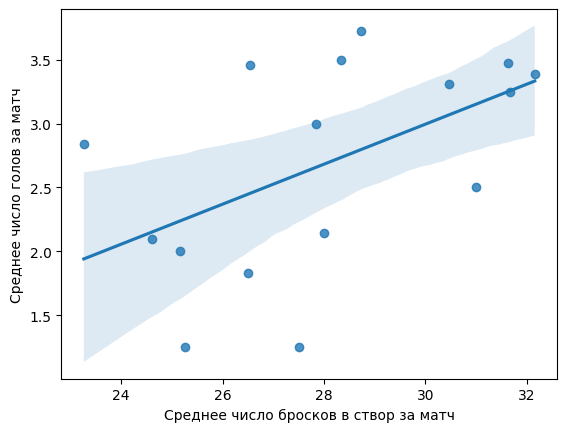

In [13]:
sns.regplot(data=avgshots, x='Shot', y='Goal', seed=0)
plt.xlabel('Среднее число бросков в створ за матч')
plt.ylabel('Среднее число голов за матч')
plt.show()
print(f"Корреляция: {avgshots['Shot'].corr(avgshots['Goal']):.3f}")

Видна положительная связь (r ≈ 0,521): команды, которые чаще бросают в створ, в среднем больше забивают. Для линейной регрессии с одним признаком и константой R² = r² ≈ 0,271. То есть линия объясняет около 27,1% разброса среднего числа голов между командами в этой выборке. Остальная часть разброса такой моделью не объясняется. Я думаю, связь заметна, но одного числа бросков недостаточно для объяснения результативности. Это сравнение всего 16 команд, и оно не доказывает причинную связь. Кроме того, голы сами входят в число бросков в створ, что тоже важно при интерпретации корреляции.

## 14. Матч с наибольшим числом всех бросков

Считаю вместе голы, отражённые броски в створ, промахи и заблокированные броски обеих команд. Здесь сравниваю общее число за матч, без пересчёта на минуту: именно такой показатель требуется в задании.

In [14]:
all_shots = events[events['Play Type'].isin(shot_types + ['blocked-shot'])]
shots_per_game = all_shots.groupby('Game ID').size()
idxmax = shots_per_game.idxmax()
print(gameInfo(idxmax))
print('Число бросков:', shots_per_game.loc[idxmax])

Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)
Число бросков: 208


## 15. Карта бросков в найденном матче

В найденном матче в нечётных периодах хозяева защищают правые ворота. Меняю знаки обеих координат в этих периодах, то есть поворачиваю площадку на 180 градусов. После этого броски хозяев направлены вправо, гостей влево. Цвет показывает исход броска, форма маркера показывает команду.

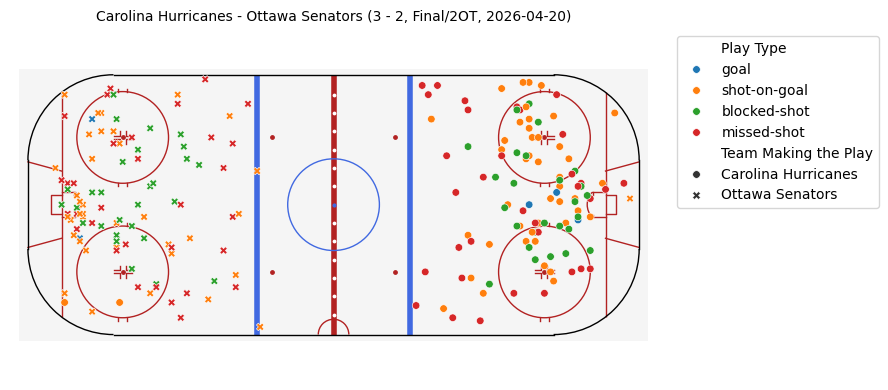

In [15]:
sys.path.insert(0, str(data_dir.resolve()))
from rink import plot_rink

match_shots = all_shots[all_shots['Game ID'].eq(idxmax)].copy()

odd_period = match_shots['Period'].mod(2).eq(1)
match_shots.loc[odd_period, ['X Coordinate on the Ice Rink', 'Y Coordinate on the Ice Rink']] *= -1

plt.figure(figsize=(9, 4))
plot_rink()
sns.scatterplot(data=match_shots, x='X Coordinate on the Ice Rink',
                y='Y Coordinate on the Ice Rink', hue='Play Type',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                style='Team Making the Play', s=30)
plt.axis('equal')
plt.axis('off')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.title(gameInfo(idxmax), fontsize=10)
plt.tight_layout()
plt.show()

## 16. Десять лучших снайперов

У событий `goal` автор гола записан в поле первого игрока. Считаю число таких событий для каждого игрока и выбираю десять наибольших значений.

In [16]:
goals = events[events['Play Type'].eq('goal')].copy()
scorers = goals['Player in the Event #1'].value_counts().rename('Goals')
display(scorers.nlargest(10))

Player in the Event #1
Brett Howden        14
Pavel Dorofeyev     12
Logan Stankoven     11
Mitch Marner        10
Nikolaj Ehlers       8
Jordan Staal         8
Nathan MacKinnon     7
Taylor Hall          7
Alex Newhook         7
Matt Boldy           7
Name: Goals, dtype: int64

## 17. Десять лучших ассистентов

Передачи могут быть записаны во втором и третьем полях. Объединяю оба поля и исключаю пропуски, чтобы учесть каждую указанную передачу.

In [17]:
assists = (goals[['Player in the Event #2', 'Player in the Event #3']]
           .stack().value_counts().rename('Assists'))
display(assists.nlargest(10))

Jack Eichel        20
Mitch Marner       19
Lane Hutson        13
Jackson Blake      13
Nick Suzuki        12
Taylor Hall        12
Martin Necas       12
Shea Theodore      12
Kirill Kaprizov    11
Quinn Hughes       11
Name: Assists, dtype: int64

## 18. Десять лучших игроков по системе «гол плюс пас»

Складываю голы и передачи по имени игрока. Если у игрока есть только голы или только передачи, отсутствующее слагаемое принимаю равным нулю.

In [18]:
points = scorers.add(assists, fill_value=0).astype(int).rename('Points')
display(points.nlargest(10))

Mitch Marner       29
Jack Eichel        22
Jackson Blake      20
Taylor Hall        19
Brett Howden       18
Nikolaj Ehlers     18
Shea Theodore      18
Lane Hutson        16
Logan Stankoven    16
Nick Suzuki        16
Name: Points, dtype: int64

## 19. Десять игроков с наибольшим средним числом бросков в створ за матч

Для среднего я беру все матчи, в которых игрок выходил на лёд, в том числе матчи без бросков. Голы тоже считаю бросками в створ.

Это среднее за сыгранный матч, время на льду здесь не учитываем. Число матчей показываю рядом, чтобы было понятно, на каком объёме данных основан результат.

In [19]:
games_played = appearances.groupby('Player')['Game ID'].nunique().rename('Games')
player_shots = (events.loc[events['Play Type'].isin(['shot-on-goal', 'goal']),
                          'Player in the Event #1'].value_counts())
shots_ranking = games_played.to_frame()
shots_ranking['Shots'] = player_shots.reindex(shots_ranking.index, fill_value=0)
shots_ranking['Shots per Game'] = shots_ranking['Shots'] / shots_ranking['Games']
display(shots_ranking.nlargest(10, 'Shots per Game').round(3))

,Games,Shots,Shots per Game
Player,,,
Jason Robertson,6,30,5.000
Dylan Guenther,6,27,4.500
Nikita Kucherov,7,31,4.429
Matt Boldy,11,48,4.364
Quinton Byfield,4,17,4.250
Darren Raddysh,7,28,4.000
Joel Eriksson Ek,6,24,4.000
Alex Laferriere,4,15,3.750
David Pastrnak,6,22,3.667


## 20. Десять игроков с наибольшим средним числом силовых приёмов за матч

Считаю только игрока, который провёл силовой приём, из первого поля события `hit`. Делитель тот же: все сыгранные им матчи, включая игры без силовых приёмов. У Turcotte и Petrovic всего по одному матчу, поэтому их среднее 6,0 может сильно измениться после следующей игры. Я думаю, по такой малой выборке нельзя уверенно судить об их обычной активности.

In [20]:
hits = events.loc[events['Play Type'].eq('hit'), 'Player in the Event #1'].value_counts()
hits_ranking = games_played.to_frame()
hits_ranking['Hits'] = hits.reindex(hits_ranking.index, fill_value=0)
hits_ranking['Hits per Game'] = hits_ranking['Hits'] / hits_ranking['Games']
display(hits_ranking.nlargest(10, 'Hits per Game').round(3))

,Games,Hits,Hits per Game
Player,,,
Lawson Crouse,6,38,6.333
Alex Turcotte,1,6,6.000
Alexander Petrovic,1,6,6.000
Yakov Trenin,9,51,5.667
Dylan Cozens,4,22,5.500
Vasily Podkolzin,6,32,5.333
Carl Grundstrom,3,15,5.000
Ivan Barbashev,22,110,5.000
Marcus Foligno,11,55,5.000


## 21. Вратари, не пропустившие ни одного гола хотя бы в одном матче

In [21]:
goalie_cols = ["Away Team's Goalie", "Home Team's Goalie"]
goalie_appearances = (events[['Game ID'] + goalie_cols]
                      .melt(id_vars='Game ID', value_name='Goalie')
                      .dropna(subset=['Goalie'])
                      .drop_duplicates(['Game ID', 'Goalie']))

empty_roster = (goals["# of Away Team's Players on the Ice"].eq(0)
                & goals["# of Home Team's Players on the Ice"].eq(0))
previous_goalies = events.groupby('Game ID')[goalie_cols].shift()
previous_play_id = events.groupby('Game ID')['Play ID'].shift()
missing_goals = goals.loc[empty_roster]
roster_evidence = missing_goals[['Game ID', 'Play ID']].rename(
    columns={'Game ID': 'Матч', 'Play ID': 'Гол (Play ID)'}
)
roster_evidence['Предыдущее событие (Play ID)'] = previous_play_id.loc[missing_goals.index].astype(int)
roster_evidence['Вратарь гостей ранее'] = previous_goalies.loc[missing_goals.index, goalie_cols[0]]
roster_evidence['Вратарь хозяев ранее'] = previous_goalies.loc[missing_goals.index, goalie_cols[1]]
roster_evidence['Оба указаны'] = previous_goalies.loc[missing_goals.index].notna().all(axis=1)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(roster_evidence.reset_index(drop=True))
print(f'Голов с пустыми составами: {len(roster_evidence)}. '
      f'Оба вратаря указаны в предыдущем событии: {roster_evidence["Оба указаны"].sum()}.')
if not roster_evidence['Оба указаны'].all():
    raise ValueError('Не для каждого гола известны оба вратаря из предыдущего события.')

,Матч,Гол (Play ID),Предыдущее событие (Play ID),Вратарь гостей ранее,Вратарь хозяев ранее,Оба указаны
0,2025030115,390,389,Jeremy Swayman,Alex Lyon,True
1,2025030121,349,348,Jakub Dobes,Andrei Vasilevskiy,True
2,2025030122,427,426,Jakub Dobes,Andrei Vasilevskiy,True
3,2025030123,317,316,Andrei Vasilevskiy,Jakub Dobes,True
4,2025030126,392,391,Andrei Vasilevskiy,Jakub Dobes,True
5,2025030132,550,549,Linus Ullmark,Frederik Andersen,True
6,2025030146,388,387,Arturs Silovs,Dan Vladar,True
7,2025030152,397,396,Anton Forsberg,Scott Wedgewood,True
8,2025030163,454,453,Jake Oettinger,Jesper Wallstedt,True
9,2025030164,402,401,Jake Oettinger,Jesper Wallstedt,True


Голов с пустыми составами: 22. Оба вратаря указаны в предыдущем событии: 22.


У 22 победных голов в овертайме составы пусты (по 0 игроков). В этих случаях считаем, что в воротах остался тот же вратарь, что и в предыдущем событии матча. В таблице выше приведены все такие голы, номера предыдущих событий и записанные там вратари. Столбец «Оба указаны» и итог под ней показывают, для скольких голов известны оба вратаря из предыдущей строки. Поэтому использую `shift()` внутри каждого матча. Он берёт именно предыдущую строку, тогда как `ffill()` ищет последнее непустое значение и может пройти через несколько пропусков. Безусловный `ffill()` мог бы ошибочно заполнить настоящие пустые ворота. Здесь восстанавливаю данные только у голов с полностью пустыми составами; остальные пропуски в поле защищающегося вратаря считаю пустыми воротами. Наличие имён в предыдущем событии видно из таблицы. Отсутствие замены между событиями остаётся допущением: отдельной записи о замене в этих данных нет.

Сначала нахожу все пары «матч, вратарь», затем считаю голы в ворота каждого из них. Выбираю вратарей с нулём пропущенных хотя бы в одной игре. Неполные матчи тоже учитываю, поэтому попадание в список не обязательно означает сухой матч целиком.

In [22]:
for col in goalie_cols:
    goals.loc[empty_roster, col] = previous_goalies.loc[missing_goals.index, col]

goals['Goalie'] = np.where(goals['Team Making the Play'].eq(goals['Home Team']),
                           goals["Away Team's Goalie"], goals["Home Team's Goalie"])
goals_against = goals.dropna(subset=['Goalie']).groupby(['Game ID', 'Goalie']).size()
goalie_games = goalie_appearances.set_index(['Game ID', 'Goalie'])
goalie_games['Goals Against'] = goals_against.reindex(goalie_games.index, fill_value=0)
zero_goalies = (goalie_games.loc[goalie_games['Goals Against'].eq(0)]
                .index.get_level_values('Goalie').unique().sort_values().tolist())
display(zero_goalies)

['Andrei Vasilevskiy',
 'Brandon Bussi',
 'Dan Vladar',
 'Frederik Andersen',
 'Joonas Korpisalo',
 'Scott Wedgewood']

## 22. Дополнительный вопрос

Как часто хозяева выигрывали матч?

Сравниваю итоговый счёт хозяев и гостей, включая овертаймы. Доля домашних побед равна числу таких побед, делённому на общее число матчей.

In [23]:
home_wins = games['Home Score'].gt(games['Away Score']).sum()
print(f'Хозяева выиграли {home_wins} из {len(games)} матчей ({home_wins / len(games):.1%}).')

Хозяева выиграли 39 из 82 матчей (47.6%).


Получилось, что с учётом овертаймов хозяева выигрывали немного реже гостей: 47,6% против 52,4%. Разница с 50% небольшая. Потому тут нельзя говорить о преимуществе или недостатке своей площадки.